## Executive summary

Symmetrix is a C++ evaluator for trained equivariant MACE models. It extracts the learned weights and radial splines from a PyTorch MACE checkpoint into a JSON file, then evaluates energies and forces through an ASE calculator or LAMMPS, on CPU or with a Kokkos-CUDA GPU path. The problem it addresses is the cost of long molecular dynamics runs with equivariant potentials, where force evaluation dominates. This demo builds a small random-weight MACE model for LiCl, extracts it, and checks that Symmetrix reproduces the reference MACE energies and forces. It then times both on CPU at 64, 216 and 512 atoms. The model is random and not physical, and the post's 100-fold GPU claim is not tested here.

## Core ideas in plain words

- **Equivariant model.** A MACE potential predicts energies that do not change under rotation or translation, and forces that rotate with the structure. Its features are spherical-harmonic channels combined with tensor products.
- **Extraction.** Symmetrix does not run PyTorch. A script (`extract_mace_data`) reads a trained MACE model, expands its radial functions into cubic splines, and writes weights and spline tables to JSON. This step needs `mace-torch` and runs once per model.
- **Native evaluator.** The JSON file is loaded into a C++ evaluator with a CPU path (OpenMP) and an optional Kokkos path (Serial or CUDA). The ASE calculator builds neighbour lists, calls the evaluator, and turns pair forces into atomic forces.
- **Same potential, different arithmetic.** Symmetrix should agree with the reference MACE to round-off in float64. Any speed difference is an implementation effect, not a change in the model.
- **Front ends.** The same JSON model is used from Python/ASE and from a LAMMPS `pair_style`. This demo covers only the ASE path.

## Install

Install the pinned environment from the kit folder:

```
pip install -r requirements.txt
```

`requirements.txt` pins every package, including the CPU PyTorch wheel. Symmetrix is installed from its GitHub commit, so this step compiles C++ code. It needs a compiler and CMake, and the build can take several minutes. The cells below assume the install succeeded; the Symmetrix cells report it if they cannot import the package.

## Step-by-step walkthrough

Task: a small LiCl rock-salt box, similar in composition to the molten-salt systems in the reader's field. We compare Symmetrix with the reference MACE calculator on a model we generate ourselves, so no checkpoint or dataset is downloaded.

### 4a. Imports and versions

In [1]:
import os, time, tempfile, shutil, warnings
# e3nn 0.4.x calls torch.load on a bundled constants file. PyTorch >= 2.6 defaults to
# weights_only=True, which rejects it. This env var restores the old behaviour for that
# trusted package file. It must be set before mace or e3nn is imported.
os.environ["TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD"] = "1"
warnings.filterwarnings("ignore")

import numpy as np
import torch
import ase
import mace
from importlib.metadata import version

torch.set_default_dtype(torch.float64)
print("python packages:", {p: version(p) for p in ["torch", "mace-torch", "ase", "numpy", "symmetrix"]})

try:
    import symmetrix
    from symmetrix import Symmetrix
    from symmetrix.extract_mace_data import extract_mace_data
    HAVE_SYM = True
except Exception as exc:
    HAVE_SYM = False
    print("Symmetrix not importable:", type(exc).__name__, str(exc)[:200])
print("Symmetrix available:", HAVE_SYM)

python packages: {'torch': '2.15.0+cpu', 'mace-torch': '0.3.17', 'ase': '3.29.0', 'numpy': '2.5.5', 'symmetrix': '0.3.1'}


cuequivariance or cuequivariance_torch is not available. Cuequivariance acceleration will be disabled.


Symmetrix available: True


### 4b. A small LiCl test structure

We use the rock-salt LiCl cell with a = 5.13 Å and tile it 2x2x2 (64 atoms). Random displacements of 0.1 Å make the forces nonzero. The seed fixes the displacement.

In [2]:
from ase.build import bulk

def make_structure(reps):
    atoms = bulk("LiCl", "rocksalt", a=5.13, cubic=True).repeat((reps, reps, reps))
    atoms.rattle(stdev=0.1, seed=1)
    return atoms

atoms64 = make_structure(2)
print(f"{len(atoms64)} atoms, cell {atoms64.cell.lengths()[0]:.2f} Å cubic, species {sorted(set(atoms64.get_chemical_symbols()))}")

64 atoms, cell 10.26 Å cubic, species ['Cl', 'Li']


### 4c. Build a small random-weight MACE model

The weights are random, so the energies are not physical. The model is two interaction layers with 16 channels and l_max = 1, which matches the structure Symmetrix supports. The model is saved to a temporary folder, not to the kit folder.

In [3]:
from e3nn import o3
from mace.modules import ScaleShiftMACE
from mace.modules.blocks import RealAgnosticInteractionBlock, RealAgnosticResidualInteractionBlock

Z = [3, 17]                      # Li, Cl
torch.manual_seed(0)
mace_model = ScaleShiftMACE(
    r_max=5.0, num_bessel=8, num_polynomial_cutoff=5, max_ell=1,
    interaction_cls=RealAgnosticResidualInteractionBlock,
    interaction_cls_first=RealAgnosticInteractionBlock,
    num_interactions=2, num_elements=2,
    hidden_irreps=o3.Irreps("16x0e + 16x1o"),
    MLP_irreps=o3.Irreps("16x0e"),
    atomic_energies=np.zeros(2),
    avg_num_neighbors=10.0,
    atomic_numbers=Z,
    correlation=2,
    gate=torch.nn.functional.silu,
    radial_MLP=[32, 32, 32],
    radial_type="bessel",
    atomic_inter_scale=1.0, atomic_inter_shift=0.0,
).to(torch.float64).eval()
n_params = sum(p.numel() for p in mace_model.parameters())
WORKDIR = tempfile.mkdtemp(prefix="symkit-")
MODEL_FILE = os.path.join(WORKDIR, "licl_random.model")
torch.save(mace_model, MODEL_FILE)
print(f"random MACE model: {n_params} parameters, float64, CPU")

random MACE model: 12896 parameters, float64, CPU


### 4d. Reference energies and forces from MACE

`MACECalculator` loads the saved model and evaluates it with PyTorch. This is the reference for the Symmetrix comparison.

In [4]:
from mace.calculators import MACECalculator

ref_calc = MACECalculator(model_paths=MODEL_FILE, device="cpu", default_dtype="float64")
atoms_ref = atoms64.copy()
atoms_ref.calc = ref_calc
E_ref = atoms_ref.get_potential_energy()
F_ref = atoms_ref.get_forces()
print(f"reference MACE energy: {E_ref:.6f} eV")
print(f"forces shape {F_ref.shape}, RMS {np.sqrt((F_ref**2).mean()):.6f} eV/Å")

reference MACE energy: -0.973140 eV
forces shape (64, 3), RMS 0.003965 eV/Å


### 4e. Extract the model and compare with Symmetrix

`extract_mace_data` writes the model to a JSON file. The Symmetrix ASE calculator then loads that file. We run the CPU path (`use_kokkos=False`), which needs no GPU and no Kokkos build. The comparison prints the energy difference and the largest force difference.

In [5]:
if HAVE_SYM:
    try:
        sym_data = extract_mace_data(MODEL_FILE, ["Li", "Cl"], None, num_spline_points=1024, r_min=0.5)
        import json
        SYM_JSON = os.path.join(WORKDIR, "licl_random.json")
        with open(SYM_JSON, "w") as fh:
            json.dump(sym_data, fh)
        sym_calc = Symmetrix(SYM_JSON, dtype="float64", use_kokkos=False)
        atoms_sym = atoms64.copy()
        atoms_sym.calc = sym_calc
        E_sym = atoms_sym.get_potential_energy()
        F_sym = atoms_sym.get_forces()
        print(f"Symmetrix energy: {E_sym:.6f} eV")
        print(f"|dE| = {abs(E_sym - E_ref):.2e} eV")
        print(f"max |dF| = {np.abs(F_sym - F_ref).max():.2e} eV/Å (max |F| = {np.abs(F_ref).max():.3e})")
    except Exception as exc:
        print("Symmetrix comparison failed:", type(exc).__name__, str(exc)[:300])
        HAVE_SYM = False
else:
    print("skipped: Symmetrix not installed")

Symmetrix energy: -0.973140 eV
|dE| = 1.56e-11 eV
max |dF| = 4.38e-09 eV/Å (max |F| = 1.309e-02)


### 4f. Timing on CPU

We time one force evaluation per call, after one warm-up call, at 64, 216 and 512 atoms. Each size is repeated three times and the mean is taken. The numbers are specific to this machine and this random model.

In [6]:
def time_forces(atoms, calc, repeats=3):
    atoms = atoms.copy()
    calc.calculate(atoms, ["energy", "forces"], ["positions"])   # warm-up
    t0 = time.perf_counter()
    for _ in range(repeats):
        calc.calculate(atoms, ["energy", "forces"], ["positions"])
    return 1e3 * (time.perf_counter() - t0) / repeats   # ms per call

import csv
rows = []
for reps in (2, 3, 4):
    atoms = make_structure(reps)
    n = len(atoms)
    t_mace = time_forces(atoms, MACECalculator(model_paths=MODEL_FILE, device="cpu", default_dtype="float64"))
    t_sym = time_forces(atoms, sym_calc) if HAVE_SYM else float("nan")
    rows.append((n, t_mace, t_sym))
    print(f"{n:4d} atoms  MACE {t_mace:9.1f} ms  Symmetrix {t_sym:9.1f} ms  ratio {t_mace / t_sym:6.1f}x")

os.makedirs("output", exist_ok=True)
with open("output/timing.csv", "w", newline="") as fh:
    w = csv.writer(fh)
    w.writerow(["n_atoms", "mace_ms", "symmetrix_ms", "mace_over_symmetrix"])
    for n, tm, ts in rows:
        w.writerow([n, f"{tm:.3f}", f"{ts:.3f}", f"{tm / ts:.2f}"])
print("saved output/timing.csv")

  64 atoms  MACE      29.5 ms  Symmetrix       1.7 ms  ratio   17.0x


 216 atoms  MACE      60.1 ms  Symmetrix       5.2 ms  ratio   11.6x


 512 atoms  MACE      98.7 ms  Symmetrix      12.4 ms  ratio    7.9x
saved output/timing.csv


### 4g. Figures

The first figure plots time per force call against system size. The second is a force parity plot for the 64-atom structure. Both are 6 by 4 inches at 100 dpi and are saved to `output/`.

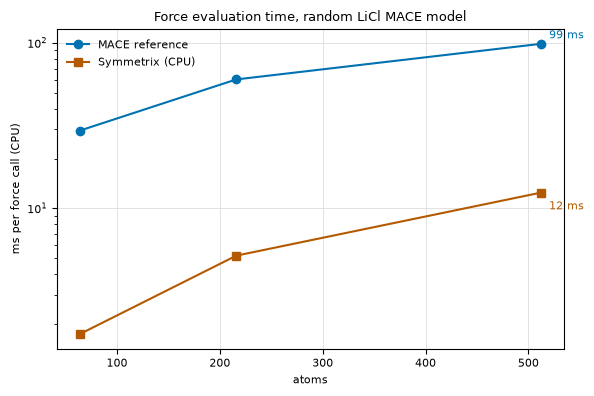

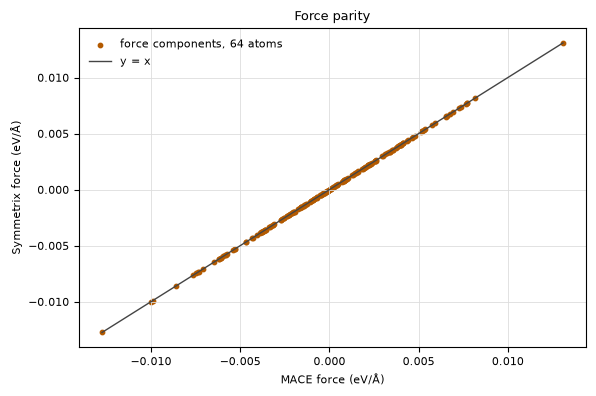

In [7]:
import matplotlib.pyplot as plt

C_MACE, C_SYM = "#0072B2", "#B35A00"   # blue and dark orange (validated for CVD; orange carries direct labels)

fig, ax = plt.subplots(figsize=(6, 4), dpi=100)
ns = [r[0] for r in rows]
ax.plot(ns, [r[1] for r in rows], "o-", color=C_MACE, lw=1.5, ms=6, label="MACE reference")
if HAVE_SYM:
    ax.plot(ns, [r[2] for r in rows], "s-", color=C_SYM, lw=1.5, ms=6, label="Symmetrix (CPU)")
    ax.annotate(f"{rows[-1][2]:.0f} ms", (ns[-1], rows[-1][2]), textcoords="offset points", xytext=(6, -12), color=C_SYM)
ax.annotate(f"{rows[-1][1]:.0f} ms", (ns[-1], rows[-1][1]), textcoords="offset points", xytext=(6, 4), color=C_MACE)
ax.set_xlabel("atoms")
ax.set_ylabel("ms per force call (CPU)")
ax.set_yscale("log")
ax.grid(True, which="major", color="#dddddd", lw=0.6)
ax.legend(frameon=False)
ax.set_title("Force evaluation time, random LiCl MACE model")
fig.tight_layout()
fig.savefig("output/timing.png", dpi=100)
plt.show()

if HAVE_SYM:
    fig, ax = plt.subplots(figsize=(6, 4), dpi=100)
    lo, hi = F_ref.min(), F_ref.max()
    ax.scatter(F_ref.ravel(), F_sym.ravel(), s=10, color=C_SYM, label="force components, 64 atoms")
    ax.plot([lo, hi], [lo, hi], color="#444444", lw=1, label="y = x")
    ax.set_xlabel("MACE force (eV/Å)")
    ax.set_ylabel("Symmetrix force (eV/Å)")
    ax.grid(True, color="#dddddd", lw=0.6)
    ax.legend(frameon=False, loc="upper left")
    ax.set_title("Force parity")
    fig.tight_layout()
    fig.savefig("output/parity.png", dpi=100)
    plt.show()
else:
    print("parity figure skipped: Symmetrix not installed")

### 4h. Clean up the temporary files

The model and JSON files were written to a temporary folder outside the kit. Remove them now.

In [8]:
shutil.rmtree(WORKDIR, ignore_errors=True)
print("temporary files removed")

temporary files removed


## Results

Saved run, from the pinned environment in `requirements.txt` (CPU, float64):

- **Energies agree.** Symmetrix and the reference MACE give the same energy, -0.973140 eV, with |dE| = 1.56e-11 eV.
- **Forces agree.** The largest force-component difference is 4.38e-9 eV/Å. The largest force in the structure is 1.31e-2 eV/Å, so the relative error is about 3e-7. The random model has small forces, so the relative number is the meaningful one.
- **Speed differs with size.** Time per force call in this run was 29 ms (MACE) against 1.8 ms (Symmetrix) at 64 atoms, 57 ms against 5.3 ms at 216 atoms, and 103 ms against 12.7 ms at 512 atoms. The ratio was 16.6x, 10.8x and 8.2x. This is one run on one CPU with a 16-channel random model, so do not read it as a general speedup.
- **Figures.** `output/timing.png` shows time against size on a log scale. `output/parity.png` shows the force parity for the 64-atom structure, where every point lies on the line y = x. The numbers are also in `output/timing.csv`.

The post's 100-fold figure is for GPU runs on unstated systems, so this CPU result does not test it.

## Gotchas found while building

1. **e3nn and `torch.load`.** With PyTorch 2.6 or later, importing `mace` through `e3nn` 0.4.x fails with an `UnpicklingError` about `slice`. The cell sets `TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD=1` before the import, which restores the old loader for the trusted package file only.
2. **Symmetrix is not on PyPI.** It is installed from the pinned commit `664edba` in `requirements.txt`. pip clones the submodules and builds the default Kokkos build, which is slow. Our first local attempt without Kokkos took several minutes and produced the same CPU results.
3. **`use_kokkos` defaults to True.** The calculator raises a `RuntimeError` if the package was built without Kokkos. The demo passes `use_kokkos=False`, which runs the CPU path.
4. **The extractor takes a whole pickled model.** `extract_mace_data` expects a file written with `torch.save(model)`, not a state dict. It also accepts only two-layer models with the block types it checks for, and fails on other architectures.
5. **Relative force error matters.** A random model has forces of about 1e-2 eV/Å, so an absolute difference of 4e-9 eV/Å looks tiny. Compare it with the largest force in the structure.
6. **Symmetrix has no `reset()`.** The ASE wrapper does not implement `reset()`, so the timing helper calls `calculate()` directly.
7. **Timing noise from other jobs.** In our first run the install was using all four cores. The MACE time at 64 atoms was 190 ms then, against 29 ms on an idle machine. Time on an idle machine and report the spread.
8. **Harmless MACE message.** The `cuequivariance ... not available` line is printed by `mace` at import time and does not affect the results.

## Limitations

- The model has random weights. Its energies and forces are not physical, so the speed result says nothing about accuracy on real materials.
- The timing covers only 64, 216 and 512 atoms on CPU, with three repeats. It is not a benchmark, and the ASE wrapper adds its own overhead to both calculators.
- The LAMMPS `pair_style` and the Kokkos-CUDA path were not run here.
- The post's 100-fold claim was not reproduced. It was made on A100 GPUs for an unstated system and checkpoint, and it is not compared with a current MACE backend.
- The separate Symmetrix-XL preprint reports 3.1 to 5.0-fold LAMMPS speedups on its own A100 and RTX 5090 tests. That is a different implementation and was not tested here.
- The 10-minute laptop demonstration in the post was not verified.

## How to adapt this to your own work

1. Replace the random model with a trained checkpoint: a MACE-MP foundation model or your own fine-tuned model. Pass its file to `extract_mace_data`. Extraction supports two-layer MACE models with the layer types the extractor checks for.
2. Change the structure. For a molten-salt study, build a LiCl–KCl or LiCl–FeCl2 box with `ase.build` or from a trajectory. Keep the element list in `extract_mace_data` in sync with the species you need.
3. Use a GPU build. With CUDA available at install time, `use_kokkos=True` runs the Kokkos-CUDA path. The Kokkos-CUDA path was not tested in this kit.
4. For production MD, run LAMMPS with `pair_style symmetrix` using the JSON file, and check energy conservation against the MACE reference on your own system.
5. Before trusting any speedup, compare energies and forces on frames from your own data, and time at your system sizes with your precision.

## Source, package, and license

- Symmetrix package: https://github.com/wcwitt/symmetrix (commit 664edba, release v0.3.1)
- Symmetrix-XL fork: https://github.com/bonan-group/symmetrix-xl
- Source post: "Symmetrix: accelerated evaluation of equivariant atomistic models" (W. C. Witt and contributors)
- Preprint on Symmetrix-XL and architecture-preserving inference: arXiv:2610.01036
- MACE: https://github.com/ACEsuit/mace
- License: MIT (Symmetrix repository)